# Lab 09 -  Time Series Analysis


In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt   # data visualization
from datetime import datetime, timedelta, timezone
np.random.seed(42)

The file `airpassenger.csv` represents a monthly survey showing the number of passengers that travel an air agency over a period of time.
### __Questions 01 to 05__ is based on this dataset.

## Question 01 

---
__a)__ Use pandas library to read the file `airpassenger.csv` and display the first 5 elements
<br>__b)__ Rename the columns into [Date, Number of passengers]
<br>__c)__ Verify the data types and convert the Date column into datetime format. [hint: `pd.to_datetime()`]

In [2]:
path = '../data/airpassenger.csv'

df = pd.read_csv(path)

df.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [3]:
df.columns = ['Date','Number of Passengers']

df.head()

,Date,Number of Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [4]:
print(df.dtypes)
df['Date'] = pd.to_datetime(df.Date)
# Alternatively:
# df.Date = df.Date.map(lambda x: datetime.strptime(x, '%Y-%m'))
print(df.dtypes)
df.head()

Date                    object
Number of Passengers     int64
dtype: object
Date                    datetime64[ns]
Number of Passengers             int64
dtype: object


,Date,Number of Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


## Question 02
---
What is the overall time-span (time difference from first date to last date) represented in this data
<br> __a)__ in number of days?
<br> __b)__ in number of weeks?

In [5]:
start = df['Date'].min()
end = df['Date'].max()
diff = end - start
days = int(diff/timedelta(days=1))
print('time-span: {:,} days'.format(days))

time-span: 4,352 days


In [6]:
weeks = int(diff/timedelta(weeks=1))
print('time-span: {:,} weeks'.format(weeks))

time-span: 621 weeks


## Question 03
---
__a)__ Determine the median date on this survey data.
<br> __b)__ Which dates correspond to the modal number of passengers? [Hint: modal ==> mode]

In [7]:
df.Date.median()

Timestamp('1954-12-16 12:00:00')

In [8]:
mode = df['Number of Passengers'].mode()[0]
df.Date.loc[df['Number of Passengers']==mode]

52   1953-05-01
69   1954-10-01
71   1954-12-01
Name: Date, dtype: datetime64[ns]

## Question 04
---
Plot the mean number of passengers for every rolling window of 12 observations (1 year) to visualize the trend over time.

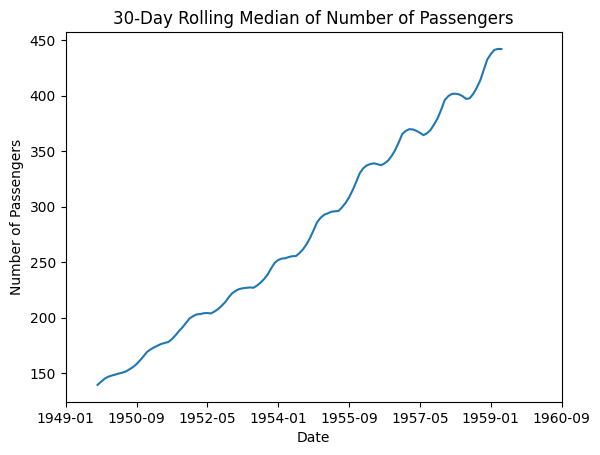

In [9]:
# Plot the rolling median
ax = df["Number of Passengers"].rolling(30).mean().plot()
xticklabels = df.Date.map(lambda t : datetime.strftime(t, '%Y-%m'))
ax.set_xticks(np.arange(20, 161, 20))
ax.set_xticklabels(xticklabels[::20])

# Add title and axis labels
ax.set_title("30-Day Rolling Median of Number of Passengers")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Passengers")

# Display the plot
plt.show()

## Question 05
---
Group the data into calender months, and [`Hint`: Add a new column with only months extracted from date]
<br> __a)__ Compute the average number of passengers for each month
<br> __b)__ Find the month with the largest number of passengers on aggregate

In [10]:
df['month'] = df.Date.dt.month_name()
# df['month'] = df.Date.map(lambda x: x.month) # Alternative
df.head()

,Date,Number of Passengers,month
0,1949-01-01,112,January
1,1949-02-01,118,February
2,1949-03-01,132,March
3,1949-04-01,129,April
4,1949-05-01,121,May


In [11]:
df.groupby(by='month') \
    .agg(lambda x: x.mean()) \
    .drop(['Date'],axis=1) \
    .round(2) \
    .rename({'Number of Passengers':'Average Number of Passengers'})

,Number of Passengers
month,
April,267.08
August,351.08
December,261.83
February,235.00
January,241.75
July,351.33
June,311.67
March,270.17
May,271.83


In [12]:
df.drop(['Date'], axis=1) \
    .groupby(['month']) \
    .agg(lambda x: x.sum()) \
    .sort_values(by=['Number of Passengers'],ascending=False) \
    .iloc[0].name

'July'

Online retail data from [UC Irvine ML repository](https://archive.ics.uci.edu/dataset/352/online+retail) containing all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail. 
### Question 06 to 10 is based on this dataset.

## Question 06
---
__a)__ Download this data and extract all transactions associated with `Norway`.
* !wget "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
* !unzip 'online+retail.zip'
<br> Note: The data is stored in .xlsx file format,  so you can use `pd.read_excel` to read it.

<br> b) Display the data type in each column
<br> c) Verify that the data has no missing values.

In [13]:
# !wget "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
# !unzip 'online+retail.zip'

In [14]:
df = pd.read_excel("Online Retail.xlsx")

In [15]:
df = df.loc[df['Country']=='Norway']
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1236,536532,84692,BOX OF 24 COCKTAIL PARASOLS,50,2010-12-01 13:24:00,0.42,12433.0,Norway
1237,536532,22444,GROW YOUR OWN PLANT IN A CAN,96,2010-12-01 13:24:00,1.06,12433.0,Norway
1238,536532,22899,CHILDREN'S APRON DOLLY GIRL,8,2010-12-01 13:24:00,2.10,12433.0,Norway
1239,536532,21156,RETROSPOT CHILDRENS APRON,8,2010-12-01 13:24:00,1.95,12433.0,Norway
1240,536532,22556,PLASTERS IN TIN CIRCUS PARADE,24,2010-12-01 13:24:00,1.65,12433.0,Norway


In [16]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [17]:
df.isnull().any(axis=0)

InvoiceNo      False
StockCode      False
Description    False
Quantity       False
InvoiceDate    False
UnitPrice      False
CustomerID     False
Country        False
dtype: bool

## Question 07
---
 __a)__ Convert the type of data in _`InvoiceDate`_ column from _datetime_ format into _string date_ format `%Y-%m-%d` [Hint: df.dt.date & datetime.strftime]
<br> __b)__ Add a new column called TotalPrice into the dataframe using the product of Quantity and UnitPrice [Hint: df.multiiply()]
<br> __c)__ Convert the data type in _`InvoiceDate`_ once again to datetime format.
<br> __d)__ Aggregate the TotalPrice by _`InvoiceDate`_ to obtain the total daily online purchases. Call the new pandas series _`df_purchase`_.

In [18]:
df.InvoiceDate = df.InvoiceDate.dt.date
df.InvoiceDate = df.InvoiceDate.map(lambda t : t.strftime('%Y-%m-%d'))

In [19]:
df['TotalPrice'] = df['Quantity'].multiply(df['UnitPrice'])

In [20]:
df.InvoiceDate = pd.to_datetime(df.InvoiceDate)

In [21]:
df_purchase = df.groupby(by=['InvoiceDate'])['TotalPrice'].agg(sum)
df_purchase.head()

InvoiceDate
2010-12-01    1919.14
2010-12-08    1867.98
2011-02-02     334.40
2011-02-16     296.50
2011-03-01     144.35
Name: TotalPrice, dtype: float64

## Question 08
---
Using pandas _`date_range`_ method: 
<br> __a)__ Compute the total purchases made during the Spring semester of 2011 (January - June). [`Hint`: df.index.isin; Answer: 6822.44]
<br> __b)__ Display all purchases made during the month of May 2011.
<br> __c)__ Compute the total weekend purchases made in the year 2011. [Answer: 419.06]


In [22]:
spring2011 = pd.date_range(start='2011-01-01', end='2011-06-30') #, freq='D')
mask = df_purchase.index.isin(spring2011)
df_purchase.loc[mask].sum()

6822.4400000000005

In [23]:
May2011 = pd.date_range('2011-05-01', '2011-05-31')
mask = df_purchase.index.isin(May2011)
df_purchase.loc[mask]

Series([], Name: TotalPrice, dtype: float64)

In [24]:
# SATURDAYS
saturdays = pd.date_range('2011-01-01', '2011-12-31', freq='W-SAT')
mask = df_purchase.index.isin(saturdays)  # boolean
total_weekend_purchases = df_purchase[mask].sum()

# SUNDAYS
sundays = pd.date_range('2011-01-01', '2011-12-31', freq='W-SUN') 
mask = df_purchase.index.isin(sundays)  # boolean
total_weekend_purchases += df_purchase.loc[mask].sum()
total_weekend_purchases

419.06

## Question 09
---
Using pandas _`date_range`_ method: 
<br>__a)__ Display a sub-dataframe with only the information for all Mondays of 2011. [`Hint`: df.isin()]
<br> __b)__ Create a sample the dataframe that includes only the last days of each month.
<br> __c)__ Display all weekly data over a period of 10 weeks beginning from May 17, 2011.


In [25]:
# Create a date range for all Mondays in 2011
mondays = pd.date_range(start='2011-01-01', end='2011-12-31', freq='W-MON')

# Filter the DataFrame for rows where the InvoiceDate falls on a Monday in 2011
mondays_invoices = df[df['InvoiceDate'].isin(mondays)]

# Display the result
mondays_invoices

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
233456,557472,21750,LARGE SKULL WINDMILL,24,2011-06-20,2.10,12432.0,Norway,50.40
233457,557472,47590B,PINK HAPPY BIRTHDAY BUNTING,3,2011-06-20,5.45,12432.0,Norway,16.35
233458,557472,47590A,BLUE HAPPY BIRTHDAY BUNTING,3,2011-06-20,5.45,12432.0,Norway,16.35
233459,557472,23049,RECYCLED ACAPULCO MAT RED,6,2011-06-20,8.25,12432.0,Norway,49.50
233460,557472,23051,RECYCLED ACAPULCO MAT BLUE,6,2011-06-20,8.25,12432.0,Norway,49.50
...,...,...,...,...,...,...,...,...,...
525799,580638,22423,REGENCY CAKESTAND 3 TIER,1,2011-12-05,12.75,12381.0,Norway,12.75
525800,580638,21976,PACK OF 60 MUSHROOM CAKE CASES,24,2011-12-05,0.55,12381.0,Norway,13.20
525801,580638,22417,PACK OF 60 SPACEBOY CAKE CASES,24,2011-12-05,0.55,12381.0,Norway,13.20
525802,580638,21212,PACK OF 72 RETROSPOT CAKE CASES,24,2011-12-05,0.55,12381.0,Norway,13.20


In [26]:
monthends = pd.date_range(start='2010-01-01', end='2011-12-31', freq='M')

mask = df['InvoiceDate'].isin(mondays)

df[mask]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
233456,557472,21750,LARGE SKULL WINDMILL,24,2011-06-20,2.10,12432.0,Norway,50.40
233457,557472,47590B,PINK HAPPY BIRTHDAY BUNTING,3,2011-06-20,5.45,12432.0,Norway,16.35
233458,557472,47590A,BLUE HAPPY BIRTHDAY BUNTING,3,2011-06-20,5.45,12432.0,Norway,16.35
233459,557472,23049,RECYCLED ACAPULCO MAT RED,6,2011-06-20,8.25,12432.0,Norway,49.50
233460,557472,23051,RECYCLED ACAPULCO MAT BLUE,6,2011-06-20,8.25,12432.0,Norway,49.50
...,...,...,...,...,...,...,...,...,...
525799,580638,22423,REGENCY CAKESTAND 3 TIER,1,2011-12-05,12.75,12381.0,Norway,12.75
525800,580638,21976,PACK OF 60 MUSHROOM CAKE CASES,24,2011-12-05,0.55,12381.0,Norway,13.20
525801,580638,22417,PACK OF 60 SPACEBOY CAKE CASES,24,2011-12-05,0.55,12381.0,Norway,13.20
525802,580638,21212,PACK OF 72 RETROSPOT CAKE CASES,24,2011-12-05,0.55,12381.0,Norway,13.20


In [27]:
weeklyMay17 = pd.date_range('2011-05-17 ', periods=10, freq='7D')
mask = df.InvoiceDate.isin(weeklyMay17)
df[mask]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
234968,557621,22761,CHEST 7 DRAWER MA CAMPAGNE,3,2011-06-21,24.95,12444.0,Norway,74.85
234969,557621,22762,CUPBOARD 3 DRAWER MA CAMPAGNE,3,2011-06-21,14.95,12444.0,Norway,44.85
234970,557621,23110,PARISIENNE KEY CABINET,2,2011-06-21,5.75,12444.0,Norway,11.50
234971,557621,23112,PARISIENNE CURIO CABINET,2,2011-06-21,7.50,12444.0,Norway,15.00
234972,557621,22782,SET 3 WICKER STORAGE BASKETS,1,2011-06-21,24.95,12444.0,Norway,24.95
...,...,...,...,...,...,...,...,...,...
235053,557621,21735,TWO DOOR CURIO CABINET,2,2011-06-21,12.75,12444.0,Norway,25.50
235054,557621,23031,DRAWER KNOB CRACKLE GLAZE PINK,12,2011-06-21,1.65,12444.0,Norway,19.80
235055,557621,23029,DRAWER KNOB CRACKLE GLAZE GREEN,12,2011-06-21,1.65,12444.0,Norway,19.80
235056,557621,23019,SMALL APOTHECARY MEASURING JAR,4,2011-06-21,8.25,12444.0,Norway,33.00


## Question 10
---
A hall is available for examinations from 1st of November 2024 until 10th of December 2024.
* Each exam slot lasts for 3 hours, 
* exams can only run on weekdays between 08:00 and 18:00,
* at least 30 minutes is allowed in-between exam slots.

Design a time series showing all possible exam slots. Values of the series are unique randomly generated integers.
<br> __a)__ Generate a date range that factors all possible exam slots, irrespective of days; and create a series using this date range as index.
<br> __b)__ Modify your series to include only hours above 0:800 and below 18:00. [Hint: index.hour]
<br> __c)__ Modify your series to exclude weekend days.
<br> __d)__ Change the values of your series using unique random integers. [`Hint`: np.random.choice]


In [28]:
exam_hours = pd.date_range('2024-11-01 08:00', '2024-12-10 18:00', freq='3h30min')
df_exam = pd.Series(0, index=exam_hours)
df_exam.head()

2024-11-01 08:00:00    0
2024-11-01 11:30:00    0
2024-11-01 15:00:00    0
2024-11-01 18:30:00    0
2024-11-01 22:00:00    0
Freq: 210T, dtype: int64

In [29]:
# include only hours above 0.800
mask = df_exam.index.hour >= 8
df_exam = df_exam[mask]

# include only hours below 18:00
mask = df_exam.index.hour < 18
df_exam = df_exam[mask]

df_exam

2024-11-01 08:00:00    0
2024-11-01 11:30:00    0
2024-11-01 15:00:00    0
2024-11-02 08:30:00    0
2024-11-02 12:00:00    0
                      ..
2024-12-09 13:00:00    0
2024-12-09 16:30:00    0
2024-12-10 10:00:00    0
2024-12-10 13:30:00    0
2024-12-10 17:00:00    0
Length: 115, dtype: int64

In [30]:
# exclude saturdays
sat = pd.date_range('2024-11-02', '2024-12-10 ', freq='W-SAT')
mask = pd.to_datetime(df_exam.index.date).isin(sat)
df_exam = df_exam[~mask]

# exclude sundays
sun = pd.date_range('2024-11-02', '2024-12-10 ', freq='W-SUN')
mask = pd.to_datetime(df_exam.index.date).isin(sun)
df_exam = df_exam[~mask]


In [31]:
# Include values for your series
num_slots = len(df_exam)
df_exam.loc[:] = np.random.choice(num_slots, replace=False, size=num_slots)
df_exam

2024-11-01 08:00:00    30
2024-11-01 11:30:00     0
2024-11-01 15:00:00    22
2024-11-04 09:30:00    31
2024-11-04 13:00:00    18
                       ..
2024-12-09 13:00:00    20
2024-12-09 16:30:00    60
2024-12-10 10:00:00    71
2024-12-10 13:30:00    14
2024-12-10 17:00:00    51
Length: 79, dtype: int64